In [7]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

In [8]:
df = pd.read_csv("Mall_Customers.csv")

In [9]:
income_col = next(c for c in df.columns if "income" in c.lower())
score_col = next(c for c in df.columns if "spending" in c.lower())
X = df[[income_col, score_col]].dropna()

scaler = StandardScaler().fit(X)
X_scaled = scaler.transform(X)

In [10]:
inertias = [KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_scaled).inertia_ for k in range(1, 11)]
ks = list(range(2, 11))
sils = [silhouette_score(X_scaled, KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(X_scaled)) for k in ks]
best_k = ks[sils.index(max(sils))]
print(f"Using k = {best_k}")

Using k = 5


In [11]:
model = KMeans(n_clusters=best_k, n_init=10, random_state=42)
labels = model.fit_predict(X_scaled)
result = df.loc[X.index].copy()
result["Cluster"] = labels
summary = result.groupby("Cluster")[[income_col, score_col]].mean().round(2)
summary["Customers"] = result["Cluster"].value_counts().sort_index()
print(summary.to_string())

         Annual Income (k$)  Spending Score (1-100)  Customers
Cluster                                                       
0                     55.30                   49.52         81
1                     86.54                   82.13         39
2                     25.73                   79.36         22
3                     88.20                   17.11         35
4                     26.30                   20.91         23


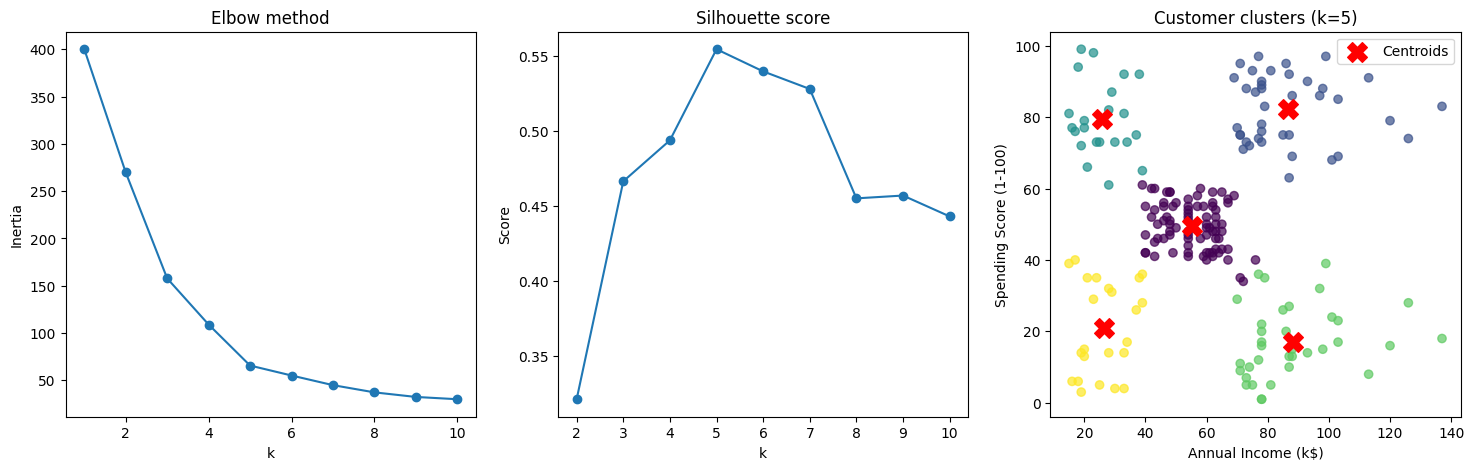

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].plot(range(1, 11), inertias, "o-"); axes[0].set(title="Elbow method", xlabel="k", ylabel="Inertia")
axes[1].plot(ks, sils, "o-"); axes[1].set(title="Silhouette score", xlabel="k", ylabel="Score")
axes[2].scatter(X[income_col], X[score_col], c=labels, cmap="viridis", alpha=0.7)
centers = scaler.inverse_transform(model.cluster_centers_)
axes[2].scatter(centers[:, 0], centers[:, 1], c="red", marker="X", s=200, label="Centroids")
axes[2].set(title=f"Customer clusters (k={best_k})", xlabel=income_col, ylabel=score_col)
axes[2].legend()
plt.show()

Path("outputs").mkdir(exist_ok=True)
result.to_csv("outputs/customer_clusters.csv", index=False)
summary.to_csv("outputs/cluster_summary.csv")